# Analyse des ventes — Pandas & Matplotlib

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
                     "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]),
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight"})

## 1. DataFrames Settings

In [3]:
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 20)
pd.set_option("display.width", 240)

pd.DataFrame(np.random.rand(200, 20))

,0,1,2,3,4,5,...,14,15,16,17,18,19
0,0.950820,0.339561,0.170172,0.033955,0.902636,0.436527,...,0.159434,0.193437,0.478961,0.988721,0.397181,0.130851
1,0.820940,0.731694,0.575570,0.003807,0.569192,0.064053,...,0.876101,0.817313,0.650864,0.288374,0.684230,0.127929
2,0.272063,0.899399,0.093057,0.512555,0.610044,0.114011,...,0.250106,0.161658,0.367736,0.910872,0.500680,0.925972
3,0.413553,0.323179,0.332336,0.613384,0.348612,0.283976,...,0.438444,0.499365,0.356532,0.401405,0.047285,0.589338
4,0.968058,0.105175,0.161693,0.786841,0.993339,0.841946,...,0.091978,0.468749,0.431089,0.360157,0.437868,0.434846
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,0.666558,0.513743,0.001353,0.095403,0.196620,0.392034,...,0.429211,0.551906,0.561957,0.584822,0.235343,0.774352
196,0.808792,0.344972,0.643166,0.908874,0.205554,0.702916,...,0.255457,0.893863,0.056163,0.963318,0.428465,0.407978
197,0.613401,0.401165,0.727337,0.931884,0.047320,0.981625,...,0.040565,0.131563,0.556799,0.547612,0.446792,0.828605
198,0.557504,0.777099,0.384441,0.548963,0.322738,0.840301,...,0.513201,0.990856,0.075133,0.957836,0.999900,0.665075


- **Series** : une colonne de valeurs d'un seul type, avec des étiquettes.
- **DataFrame** : un tableau = plusieurs Series qui partagent le même index.
- **Index** : Axe d'étiquette, identifie une ligne.

## 2. Chargement et exploration

In [6]:
xls = pd.read_excel("data/CC-AIBD-DataAnalyse-donnees.xlsx", sheet_name=None)
orders      = xls["Sales Order_data"]
territories = xls["Sales Territory_data"]
sales       = xls["Sales_data"]
resellers   = xls["Reseller_data"]
dates       = xls["Date_data"]
products    = xls["Product_data"]
customers   = xls["Customer_data"]
tables = {"orders": orders, "territories": territories, "sales": sales, "resellers": resellers,
          "dates": dates, "products": products, "customers": customers}

for name, df in tables.items():
    print(f"\n===== {name} =====")
    display(df.head())
    df.info()
    display(df.describe())


===== orders =====


,Channel,SalesOrderLineKey,Sales Order,Sales Order Line
0,Reseller,43659001,SO43659,SO43659 - 1
1,Reseller,43659002,SO43659,SO43659 - 2
2,Reseller,43659003,SO43659,SO43659 - 3
3,Reseller,43659004,SO43659,SO43659 - 4
4,Reseller,43659005,SO43659,SO43659 - 5


<class 'pandas.DataFrame'>
RangeIndex: 121253 entries, 0 to 121252
Data columns (total 4 columns):
 #   Column             Non-Null Count   Dtype
---  ------             --------------   -----
 0   Channel            121253 non-null  str  
 1   SalesOrderLineKey  121253 non-null  int64
 2   Sales Order        121253 non-null  str  
 3   Sales Order Line   121253 non-null  str  
dtypes: int64(1), str(3)
memory usage: 3.7 MB


,SalesOrderLineKey
count,1.212530e+05
mean,5.782642e+07
std,9.009990e+06
min,4.365900e+07
25%,4.987905e+07
50%,5.702800e+07
75%,6.549000e+07
max,7.512300e+07



===== territories =====


...

,ProductKey,Standard Cost,List Price
count,397.000000,397.000000,397.000000
mean,408.000000,436.454083,751.106791
std,114.748275,497.076884,837.991094
min,210.000000,0.856500,2.290000
25%,309.000000,37.120900,69.990000
50%,408.000000,204.625100,364.090000
75%,507.000000,660.914200,1214.850000
max,606.000000,2171.294200,3578.270000



===== customers =====


,CustomerKey,Customer ID,Customer,City,State-Province,Country-Region,Postal Code
0,-1,[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable],[Not Applicable]
1,11000,AW00011000,Jon Yang,Rockhampton,Queensland,Australia,4700
2,11001,AW00011001,Eugene Huang,Seaford,Victoria,Australia,3198
3,11002,AW00011002,Ruben Torres,Hobart,Tasmania,Australia,7001
4,11003,AW00011003,Christy Zhu,North Ryde,New South Wales,Australia,2113


<class 'pandas.DataFrame'>
RangeIndex: 18485 entries, 0 to 18484
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CustomerKey     18485 non-null  int64
 1   Customer ID     18485 non-null  str  
 2   Customer        18485 non-null  str  
 3   City            18485 non-null  str  
 4   State-Province  18485 non-null  str  
 5   Country-Region  18485 non-null  str  
 6   Postal Code     18485 non-null  str  
dtypes: int64(1), str(6)
memory usage: 1011.0 KB


,CustomerKey
count,18485.000000
mean,20240.404923
std,5337.947953
min,-1.000000
25%,15620.000000
50%,20241.000000
75%,24862.000000
max,29483.000000


Types à corriger, tous dans `sales` (page `Sales_data` du fichier excel) :
- `OrderDateKey` et `DueDateKey` : dates stockées en entier `AAAAMMJJ` → à convertir en `datetime`.
- `ShipDateKey` : dates stockées en entier `AAAAMMJJ` mais en `float` → à convertir en `datetime`.
- `Unit Price Discount Pct` : entier alors que c'est un pourcentage → à convertir en decimal.
- `ResellerKey`, `CustomerKey` : la valeur `-1` signifie « aucun » (voir la ligne `[Not Applicable]` dans `resellers` et `customers`) → à exclure avant d'analyser les clients ou les revendeurs.

In [8]:
cost = products["Standard Cost"] #On extrait la colonne du cout de fabrication de chaque produit
print("Médiane :", cost.median(), "| Écart-type :", cost.std().__round__(2), "| Variance :", cost.var().__round__(2))
products.groupby("Category")["Standard Cost"].agg(["median", "std", "var"])

Médiane : 204.6251 | Écart-type : 497.08 | Variance : 247085.43


,median,std,var
Category,,,
Accessories,11.2163,13.127986,172.344014
Bikes,713.0798,552.407211,305153.726769
Clothing,26.1763,12.424381,154.365235
Components,187.1571,280.636563,78756.880441


## 3. Nettoyage

In [22]:
# Pour chaque table, liste les colonnes qui contiennent au moins une valeur vide
for name, df in tables.items():
    print(name, df.columns[df.isna().any()].tolist()) 

orders []
territories []
sales ['ShipDateKey', 'ShipDate']
resellers []
dates []
products []
customers []


- `Color` vide = le texte « NA » (produit sans couleur) → on remet « NA ».
- `ShipDateKey` vide = commandes de juin 2020 pas encore expédiées → on garde le vide.

In [15]:
products["Color"] = products["Color"].fillna("NA")

Pour vérifier le total des ventes on reprend le montant avant remise, on réapplique la remise dessus et on compare à ce quie st facturé.
Vérification du total : `Sales Amount` (montant après remise) devrait valoir `Extended Amount × (1 − remise)`.

In [16]:
ok = np.isclose(sales["Extended Amount"] * (1 - sales["Unit Price Discount Pct"]), sales["Sales Amount"])
print("Lignes incorrectes :", (~ok).sum(), "| remises présentes :", sales["Unit Price Discount Pct"].unique())

Lignes incorrectes : 0 | remises présentes : [0.   0.02 0.05 0.1  0.35 0.3  0.15 0.2  0.4 ]


Les remises sont à 0 car stockées en entier ; on les recalcule à partir des montants :
- `Sales Amount / Extended Amount` = part du prix réellement payée (ex. 0,95 = 95 % payé).
- `1 − cette part` = part non payée, c'est-à-dire la remise (ex. 0,05 = 5 %).
- `value_counts()` compte ensuite combien de ventes ont chaque niveau de remise.

In [13]:
sales["Unit Price Discount Pct"] = (1 - sales["Sales Amount"] / sales["Extended Amount"]).round(2)
sales["Unit Price Discount Pct"].value_counts()

Unit Price Discount Pct
0.00    117971
0.02      1310
0.05       606
0.15       590
0.20       231
0.10       178
0.40       169
0.35       137
0.30        61
Name: count, dtype: int64

In [21]:
products["Price ratio"] = products["List Price"] / products["Standard Cost"] # Combien de fois le prix de vente est supérieur au coût de fabrication
orders["Line number"] = orders["Sales Order Line"].str.split(" - ").str[1].astype(int) # On extrait le numéro de ligne de commande à partir de la colonne "Sales Order Line"

# On convertit les colonnes de dates au format datetime
for col in ["OrderDateKey", "DueDateKey", "ShipDateKey"]:
    sales[col.replace("Key", "")] = pd.to_datetime(sales[col].astype("Int64").astype(str), format="%Y%m%d", errors="coerce")
# On calcule la marge pour chaque ligne de vente
sales["Margin"] = sales["Sales Amount"] - sales["Total Product Cost"]
print(sales[["Sales Amount", "Total Product Cost", "Margin"]].head())
sales.dtypes

   Sales Amount  Total Product Cost    Margin
0      2024.994           1898.0944  126.8996
1      6074.982           5694.2832  380.6988
2      2024.994           1898.0944  126.8996
3      2039.994           1912.1544  127.8396
4      2039.994           1912.1544  127.8396


SalesOrderLineKey                   int64
ResellerKey                         int64
CustomerKey                         int64
ProductKey                          int64
OrderDateKey                        int64
DueDateKey                          int64
ShipDateKey                       float64
SalesTerritoryKey                   int64
Order Quantity                      int64
Unit Price                        float64
Extended Amount                   float64
Unit Price Discount Pct           float64
Product Standard Cost             float64
Total Product Cost                float64
Sales Amount                      float64
OrderDate                  datetime64[us]
DueDate                    datetime64[us]
ShipDate                   datetime64[us]
Margin                            float64
dtype: object

## 4. Analyse exploratoire
On fusionne une première fois pour avoir le pays, le modèle et le canal sur chaque vente.

In [24]:
# On fusionne les tables pour obtenir un DataFrame complet par ligne de vente, avec toutes les informations sur le produit, le territoire et la commande 
df = (sales.merge(territories, on="SalesTerritoryKey")
           .merge(products, on="ProductKey")
           .merge(orders, on="SalesOrderLineKey"))

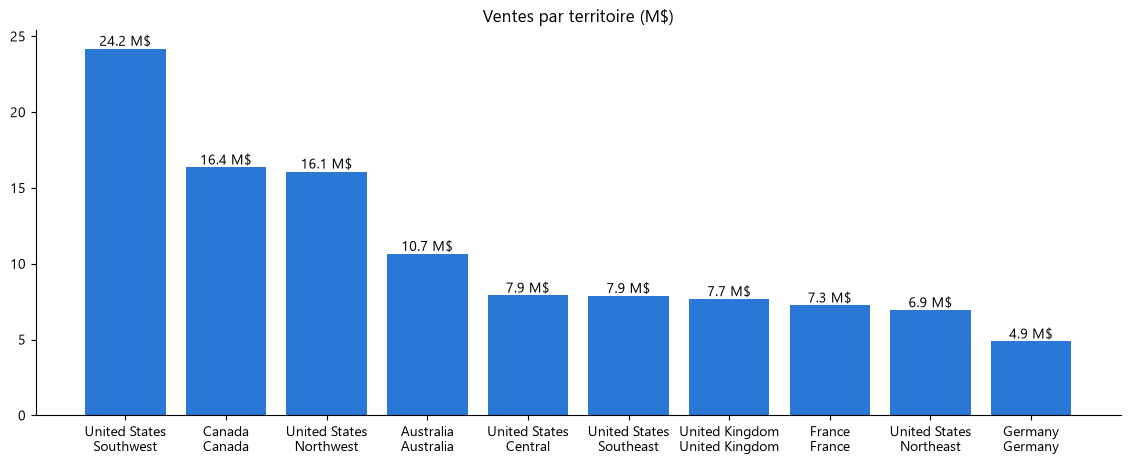

In [25]:
by_terr = df.groupby(["Country", "Region"])["Sales Amount"].sum().sort_values(ascending=False)
labels = [f"{c}\n{r}" for c, r in by_terr.index]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.bar(labels, by_terr.values / 1e6)
ax.bar_label(bars, fmt="%.1f M$")
ax.set_title("Ventes par territoire (M$)")
fig.savefig("figures/ventes_territoire.png")

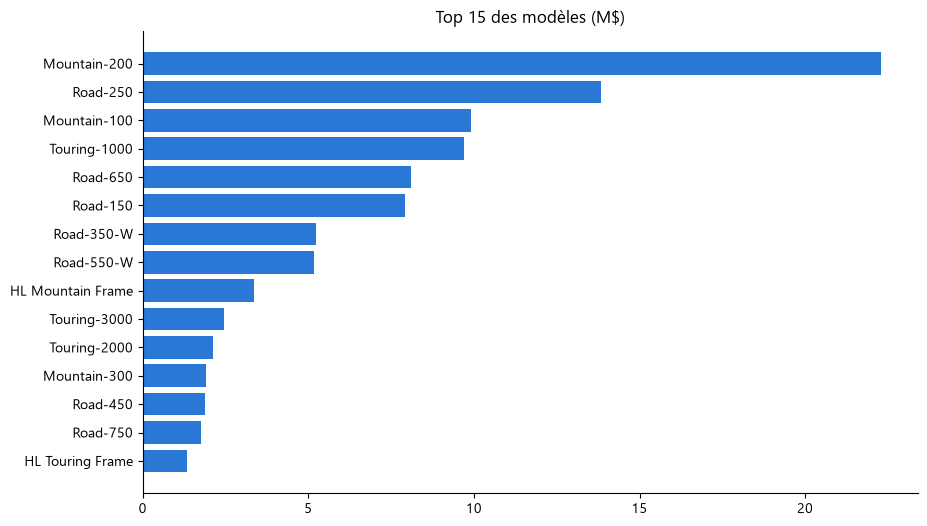

In [26]:
by_model = df.groupby("Model")["Sales Amount"].sum().nlargest(15).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(by_model.index, by_model.values / 1e6)
ax.set_title("Top 15 des modèles (M$)")
fig.savefig("figures/ventes_modele.png")

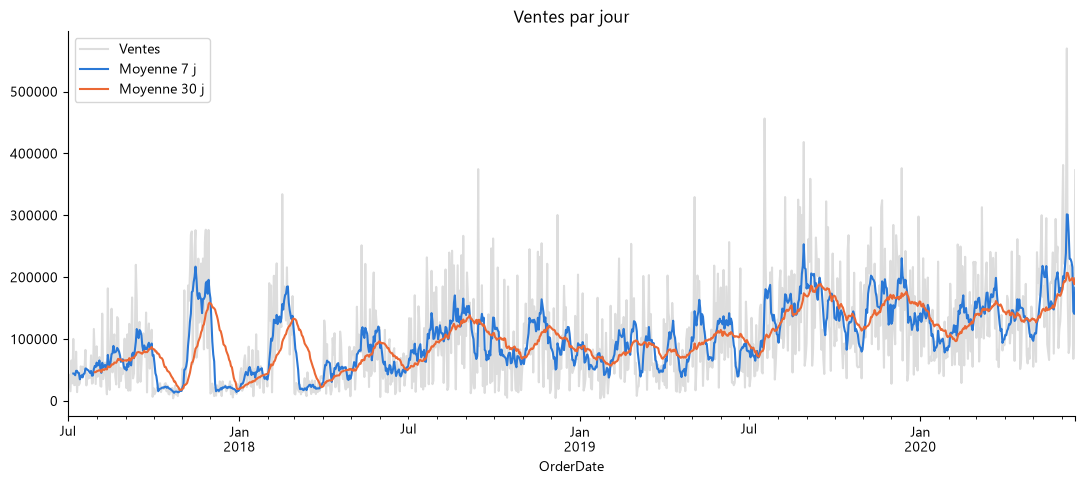

In [27]:
daily = sales.groupby("OrderDate")["Sales Amount"].sum().asfreq("D", fill_value=0).to_frame("Ventes")
daily["Moyenne 7 j"] = daily["Ventes"].rolling(7).mean()
daily["Moyenne 30 j"] = daily["Ventes"].rolling(30).mean()

ax = daily.plot(figsize=(13, 5), color=["#dddddd", "#2a78d6", "#eb6834"], title="Ventes par jour")
ax.figure.savefig("figures/ventes_jour.png")

In [28]:
df.pivot_table(index="Category", columns="Country", values="Sales Amount", aggfunc="sum", margins=True)

Country,Australia,Canada,France,Germany,United Kingdom,United States,All
Category,,,,,,,
Accessories,1.626382e+05,2.215052e+05,1.114385e+05,9.731566e+04,1.192231e+05,5.599373e+05,1.272058e+06
Bikes,1.017587e+07,1.345768e+07,6.114241e+06,4.351530e+06,6.688590e+06,5.383261e+07,9.462053e+07
Clothing,1.131758e+05,4.321123e+05,1.551274e+05,9.518483e+04,1.510683e+05,1.170945e+06,2.117613e+06
Components,2.036513e+05,2.244470e+06,8.707483e+05,3.342699e+05,7.118398e+05,7.434097e+06,1.179908e+07
All,1.065534e+07,1.635577e+07,7.251556e+06,4.878300e+06,7.670721e+06,6.299759e+07,1.098093e+08


## 5. Statistiques

In [29]:
df.groupby("Country")["Sales Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Country,,,,,,,,
Australia,15058.0,707.619602,1119.895723,2.290,8.990,35.000,1120.490,17616.3700
Canada,19064.0,857.940121,1688.137047,1.374,26.724,127.800,890.820,23020.1318
France,9088.0,797.926458,1583.301934,2.290,21.490,64.788,923.388,23667.8549
Germany,7464.0,653.577221,1263.609925,1.374,8.990,35.000,769.490,19930.8252
United Kingdom,10426.0,735.730006,1402.643964,1.374,9.990,53.990,890.820,22422.1784
United States,60153.0,1047.289258,1898.068414,1.374,34.990,218.682,1295.988,27893.6190


In [ ]:
# Savoir si les ventes et la marge sont corrélées, et si le coût de fabrication et la marge sont corrélés
print("Ventes / marge :", round(df["Sales Amount"].corr(df["Margin"]), 2))
print("Coût / marge   :", round(df["Total Product Cost"].corr(df["Margin"]), 2))

Ventes / marge : 0.2
Coût / marge   : -0.04


In [33]:
# Additionne les ventes par pays et par modèle, puis affiche les 3 pays et les 5 modèles qui ont généré le plus de ventes
print(df.groupby("Country")["Sales Amount"].sum().nlargest(3))
print(df.groupby("Model")["Sales Amount"].sum().nlargest(5))

Country
United States    6.299759e+07
Canada           1.635577e+07
Australia        1.065534e+07
Name: Sales Amount, dtype: float64
Model
Mountain-200    2.228617e+07
Road-250        1.382872e+07
Mountain-100    9.910079e+06
Touring-1000    9.715802e+06
Road-650        8.087521e+06
Name: Sales Amount, dtype: float64


Test de Levene : H0 = même écart-type dans tous les territoires. Si p < 0,05, on rejette H0.

In [ ]:
# On teste si les variances des ventes par pays sont homogènes (test de Levene)
groups = [g["Sales Amount"] for _, g in df.groupby("Country")]
print("p-value :", stats.levene(*groups).pvalue)

p-value : 1.0694187548600486e-171


## 6. Visualisation avancée

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
pts = ax.scatter(df["Sales Amount"], df["Margin"], c=df["Unit Price"], s=4, alpha=0.4)
fig.colorbar(pts, label="Prix unitaire")
ax.set(xlabel="Ventes", ylabel="Marge", title="Ventes vs marge")
fig.savefig("figures/scatter.png")

In [ ]:
model_terr = df.groupby(["Country", "Model"])["Sales Amount"].sum().reset_index()

fig, ax = plt.subplots(figsize=(11, 5))
model_terr.boxplot(column="Sales Amount", by="Country", ax=ax)
ax.set_yscale("log")
ax.set_title("CA des modèles par territoire")
fig.suptitle("")
fig.savefig("figures/boxplot.png")

In [ ]:
corr = df[["Sales Amount", "Margin", "Total Product Cost", "Unit Price"]].corr()

fig, ax = plt.subplots()
im = ax.imshow(corr, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(4), corr.columns, rotation=45)
ax.set_yticks(range(4), corr.columns)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center")
fig.colorbar(im)
ax.set_title("Corrélations")
fig.savefig("figures/heatmap.png")

In [ ]:
share = df.groupby("Country")["Sales Amount"].sum()

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(share, labels=share.index, autopct=lambda p: f"{p:.0f} %\n{p * share.sum() / 1e8:.1f} M$")
ax.set_title("Part du CA par pays")
fig.savefig("figures/camembert.png")

## 7. Analyse temporelle

In [ ]:
ts = sales.set_index("OrderDate")["Sales Amount"]
monthly = ts.resample("MS").sum()
print(ts.resample("QS").sum())
print(ts.resample("YS").sum())

monthly.plot(figsize=(12, 4), marker="o", title="CA mensuel").figure.savefig("figures/mensuel.png")

Bougies : pour chaque mois, ventes du 1er jour (ouverture), du dernier (clôture), du plus haut et du plus bas.

In [ ]:
ohlc = daily["Moyenne 7 j"].resample("MS").agg(["first", "max", "min", "last"])
color = np.where(ohlc["last"] >= ohlc["first"], "green", "red")

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(ohlc.index, ohlc["max"] - ohlc["min"], bottom=ohlc["min"], width=3, color=color)
ax.bar(ohlc.index, ohlc["last"] - ohlc["first"], bottom=ohlc["first"], width=18, color=color)
ax.set_title("Bougies mensuelles")
fig.savefig("figures/bougies.png")

## 8. Fusion complète
`how="left"` garde toutes les ventes ; on vérifie qu'aucune ligne n'est perdue ni dupliquée.

In [ ]:
full = (df.merge(resellers, on="ResellerKey", how="left", suffixes=("", "_res"))
          .merge(customers, on="CustomerKey", how="left", suffixes=("", "_cust"))
          .merge(dates, left_on="OrderDateKey", right_on="DateKey", how="left"))
assert len(full) == len(sales)

In [ ]:
full.pivot_table(index="Product", columns="Country", values="Sales Amount", aggfunc="sum").head(10)

In [ ]:
products.groupby("Model")["ProductKey"].count().sort_values(ascending=False).head(10)

In [ ]:
clients = full[full["CustomerKey"] != -1].groupby("Customer")
print(clients["Sales Order"].nunique().nlargest(5))
print(clients["Sales Amount"].sum().nlargest(5))
print("Clients avec une seule commande :", (clients["Sales Order"].nunique() == 1).mean())

In [ ]:
pd.crosstab(full["Category"], full["Country"])

In [ ]:
global_view = full.pivot_table(index=full["OrderDate"].dt.to_period("M"), columns="Category", values="Sales Amount", aggfunc="sum", fill_value=0)
global_view.plot(figsize=(12, 5), title="CA mensuel par catégorie").figure.savefig("figures/global.png")